# Анализ мобильной игры

Цель проекта: рассчитать удержание игроков, сравнить монетизацию двух вариантов акционных предложений и определить метрики тематического игрового события.

1. [Когортный анализ удержания](#task-1).
2. [Анализ A/B-теста](#task-2).
3. [Метрики игровых событий](#task-3).

[Итоги проекта](#summary).


## Данные

| Файл | Содержание | Строки | Поля |
| --- | --- | ---: | --- |
| `data/problem1-reg_data.csv` | Регистрации игроков | 1 000 000 | `reg_ts`, `uid` |
| `data/problem1-auth_data_part*.csv` | События авторизации | 9 601 013 | `auth_ts`, `uid` |
| `data/problem2.csv` | Выручка пользователей A/B-теста | 404 770 | `user_id`, `revenue`, `testgroup` |

Время регистрации и авторизации задано в Unix-секундах. Расчет календарных дат использует UTC. Период регистраций и авторизаций: с 18.11.1998 09:43:43 до 23.09.2020 15:17:24 UTC. В таблице регистраций одна строка соответствует одному игроку, в журнале авторизаций одному входу, в A/B-тесте одному пользователю за период эксперимента.

Анализ использует все строки трех таблиц. Горизонт retention составляет от 0 до 30 дней после регистрации. Матрица retention, таблицы A/B-анализа и графики сохраняются в `full_results/`.


## Окружение и параметры

Обработка данных использует `pandas` и `numpy`, визуализация `matplotlib`, тест двух пропорций `statsmodels`. Уровень значимости составляет 0,05. Bootstrap включает 1 000 повторов с фиксированным `random_state=42`.


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:,.4f}'.format)

DATA_DIR = Path('data')
RESULTS_DIR = Path('full_results')
RESULTS_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
N_BOOTSTRAP = 1000
ALPHA = 0.05

<a id="task-1"></a>
# Задание 1. Когортный анализ удержания

## Постановка задачи

Разработать функцию расчета дневного retention по таблицам регистраций и авторизаций. Когорта определяется календарной датой регистрации, день жизни игрока разностью календарных дат авторизации и регистрации в UTC.

- `uid`: идентификатор игрока.
- `reg_ts`: время регистрации в Unix-секундах.
- `auth_ts`: время авторизации в Unix-секундах.

Для когорты $c$ и дня жизни $d$:

$$Retention_{c,d}=\frac{\text{Число уникальных игроков когорты }c\text{, активных в день }d}{\text{Число зарегистрированных игроков когорты }c}\times100\%.$$

Повторные входы игрока в один календарный день учитываются один раз. Если в наблюдаемый день не активен ни один игрок когорты, retention равен 0%. Дни за пределами наблюдения обозначаются `NaN`.


## Функция расчета

`calculate_retention` принимает таблицы регистраций и авторизаций и возвращает матрицу «дата регистрации × день жизни». Параметр `max_day` задает горизонт расчета, `observation_end` конец наблюдения. При отсутствии явного конца наблюдения функция использует максимальную дату авторизации.

Функция работает с копиями входных данных, исключает повторные идентификаторы в таблице регистраций и повторные сочетания игрока и даты входа. Объединение использует `uid` и проверку связи «много авторизаций к одной регистрации». События до даты регистрации исключаются. Размер когорты рассчитывается по всем зарегистрированным игрокам, включая не вернувшихся в последующие дни.


In [2]:
def calculate_retention(reg, auth, max_day=30, observation_end=None):
    reg = reg[['uid', 'reg_ts']].copy()
    auth = auth[['uid', 'auth_ts']].copy()

    reg['reg_date'] = pd.to_datetime(reg['reg_ts'], unit='s', utc=True).dt.normalize()
    auth['auth_date'] = pd.to_datetime(auth['auth_ts'], unit='s', utc=True).dt.normalize()

    if observation_end is None:
        observation_end = auth['auth_date'].max()
    else:
        observation_end = pd.to_datetime(observation_end, utc=True).normalize()

    reg = reg.drop_duplicates(subset='uid')
    auth = auth.drop_duplicates(subset=['uid', 'auth_date'])

    df = auth.merge(reg[['uid', 'reg_date']], on='uid', how='inner', validate='many_to_one')
    df['lifetime_day'] = (df['auth_date'] - df['reg_date']).dt.days
    df = df.loc[df['lifetime_day'].ge(0)]

    if max_day is not None:
        df = df.loc[df['lifetime_day'].le(max_day)]

    cohort_size = reg.groupby('reg_date')['uid'].nunique()
    returned = df.groupby(['reg_date', 'lifetime_day'])['uid'].nunique()
    counts = returned.unstack('lifetime_day', fill_value=0)

    if max_day is not None:
        days = range(max_day + 1)
    else:
        days = range(int(df['lifetime_day'].max()) + 1) if not df.empty else range(0)
    counts = counts.reindex(index=cohort_size.index, columns=days, fill_value=0)
    retention = counts.div(cohort_size, axis=0).mul(100)

    if pd.isna(observation_end):
        retention.loc[:, :] = np.nan
    else:
        for day in retention.columns:
            retention.loc[retention.index + pd.Timedelta(days=int(day)) > observation_end, day] = np.nan

    retention.index.name = 'registration_date'
    retention.columns.name = 'lifetime_day'

    return retention


## Расчет retention

Расчет выполняется по полному набору игроков: `USE_SAMPLE=False`. Журнал авторизаций хранится в семи CSV-частях. Части читаются последовательно, каждая блоками по 1 000 000 строк. Все строки участвуют в расчете. Конец наблюдения определяется по максимальному времени авторизации во всем журнале.


In [3]:
reg_path = DATA_DIR / 'problem1-reg_data.csv'
auth_paths = sorted(DATA_DIR.glob('problem1-auth_data_part*.csv'))
USE_SAMPLE = False
SAMPLE_FRACTION = 0.05

reg = pd.read_csv(reg_path, sep=';', dtype={'uid': 'int64', 'reg_ts': 'int64'})

if USE_SAMPLE:
    sample_uids = reg['uid'].drop_duplicates().sample(frac=SAMPLE_FRACTION, random_state=RANDOM_STATE)
    reg_work = reg.loc[reg['uid'].isin(sample_uids)].copy()
else:
    reg_work = reg

auth_parts = []
last_auth_ts = None
for auth_path in auth_paths:
    for chunk in pd.read_csv(auth_path, sep=';', dtype={'uid': 'int64', 'auth_ts': 'int64'},
                             chunksize=1_000_000):
        if not chunk.empty:
            chunk_max_ts = int(chunk['auth_ts'].max())
            last_auth_ts = chunk_max_ts if last_auth_ts is None else max(last_auth_ts, chunk_max_ts)
        if USE_SAMPLE:
            chunk = chunk.loc[chunk['uid'].isin(sample_uids)].copy()
        if not chunk.empty:
            auth_parts.append(chunk)

auth_work = (pd.concat(auth_parts, ignore_index=True) if auth_parts else
             pd.DataFrame({'uid': pd.Series(dtype='int64'), 'auth_ts': pd.Series(dtype='int64')}))
del auth_parts
observation_end = (pd.to_datetime(last_auth_ts, unit='s', utc=True)
                   if last_auth_ts is not None else pd.NaT)
retention_matrix = calculate_retention(reg_work, auth_work, max_day=30,
                                       observation_end=observation_end)
retention_matrix.to_csv(RESULTS_DIR / 'retention_matrix.csv')
print(f'Retention: {len(reg_work):,} пользователей; {len(auth_work):,} событий; '
      f'{len(retention_matrix):,} когорт; дни 0–30; USE_SAMPLE={USE_SAMPLE}')
display(retention_matrix.head())


Retention: 1,000,000 пользователей; 9,601,013 событий; 5,110 когорт; дни 0–30; USE_SAMPLE=False


lifetime_day,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,...,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30
registration_date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1998-11-18 00:00:00+00:00,100.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1999-07-22 00:00:00+00:00,100.0000,0.0000,0.0000,100.0000,0.0000,0.0000,0.0000,0.0000,0.0000,100.0000,0.0000,0.0000,0.0000,0.0000,100.0000,...,0.0000,0.0000,0.0000,0.0000,100.0000,0.0000,0.0000,100.0000,0.0000,0.0000,0.0000,100.0000,0.0000,100.0000,0.0000
2000-01-13 00:00:00+00:00,100.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2000-05-28 00:00:00+00:00,100.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2000-09-16 00:00:00+00:00,100.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


## Тепловая карта retention

Тепловая карта показывает последние 20 когорт, зарегистрированных с 04.09.2020 по 23.09.2020, и дни жизни от 0 до 30. Цвет соответствует доле активных игроков когорты в процентах. Пустые области обозначают дни, которые еще не наступили к концу наблюдения.

Конец журнала приходится на 23.09.2020 15:17:24 UTC. Последний календарный день представлен частично; значения, рассчитанные по активности в этот день, не охватывают полные сутки. 


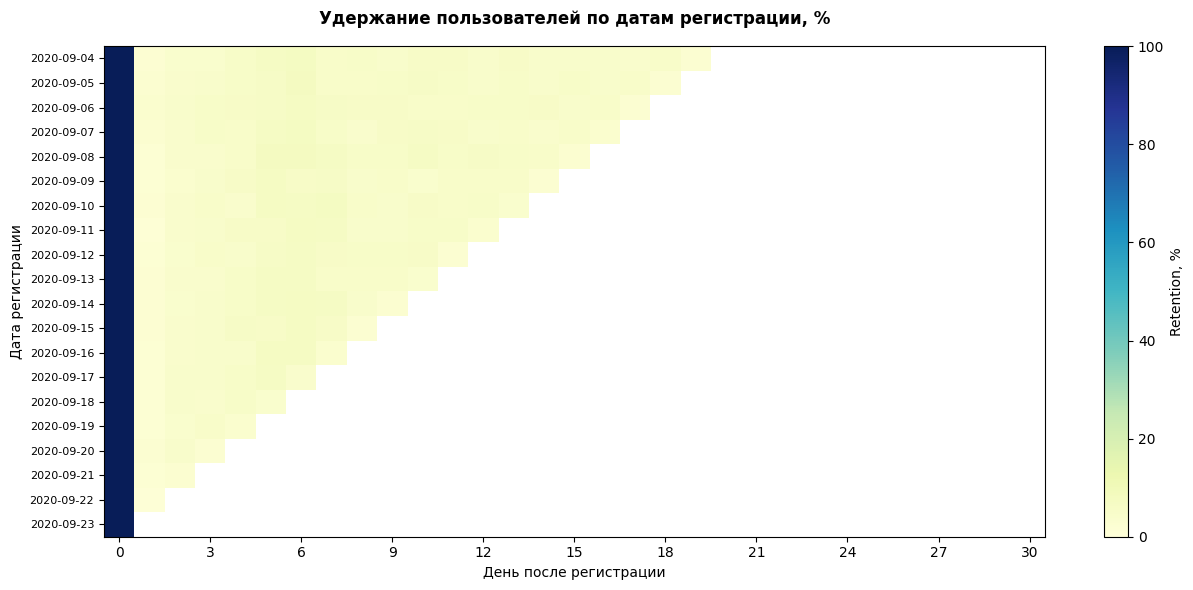

In [4]:
if 'retention_matrix' in globals():
    last_auth_date = (pd.to_datetime(last_auth_ts, unit='s', utc=True).normalize()
                      if last_auth_ts is not None else pd.NaT)
    plot_data = retention_matrix.copy()

    for day in plot_data.columns:
        plot_data.loc[plot_data.index + pd.Timedelta(days=int(day)) > last_auth_date, day] = np.nan

    plot_data = plot_data.tail(20)
    fig, ax = plt.subplots(figsize=(13, 6))
    heat = ax.imshow(plot_data.to_numpy(), aspect='auto', cmap='YlGnBu', vmin=0)
    ax.set_title('Удержание пользователей по датам регистрации, %', weight='bold', pad=16)
    ax.set_xlabel('День после регистрации')
    ax.set_ylabel('Дата регистрации')
    ax.set_xticks(np.arange(0, len(plot_data.columns), 3))
    ax.set_xticklabels(plot_data.columns[::3])
    ax.set_yticks(np.arange(len(plot_data.index)))
    ax.set_yticklabels(plot_data.index.strftime('%Y-%m-%d'), fontsize=8)
    fig.colorbar(heat, ax=ax, label='Retention, %')
    plt.tight_layout()
    fig.savefig(RESULTS_DIR / 'retention_heatmap.png', dpi=160, bbox_inches='tight')
    plt.show()

## Результаты и интерпретация

Матрица содержит 5 110 когорт и 31 столбец для дней жизни от 0 до 30. D0 равен 100% во всех когортах: первый вход каждого игрока в журнале совпадает со временем регистрации.

Retention измеряет активность в конкретный день после регистрации. Возврат в день 7 не требует активности в день 1, поэтому значения по дням не обязаны убывать последовательно.

Последние 20 когорт еще не достигли дня 30. На тепловой карте D30 для них обозначен `NaN`. Сравнение D1, D7 и D30 выполняется по когортам с соответствующим сроком наблюдения.


<a id="task-2"></a>
# Задание 2. Анализ A/B-теста монетизации

## Постановка задачи

Сравнить два набора акционных предложений мобильной игры и оценить, подтверждают ли результаты преимущество тестового варианта. Группа A является контрольной, группа B тестовой. Поле `revenue` содержит суммарную выручку пользователя за период эксперимента, `testgroup` принимает значения `a` и `b`.

## Метрики

| Метрика | Определение |
| --- | --- |
| CR в оплату | Число пользователей с `revenue > 0`, деленное на число пользователей группы |
| ARPU | Суммарная выручка, деленная на число пользователей группы |
| ARPPU | Суммарная выручка, деленная на число платящих пользователей группы |

В расчетах CR выражается долей от 0 до 1; для текстового представления используется процент. При таком определении выполняется равенство `ARPU = CR × ARPPU`. Денежные показатели выражены в единицах поля `revenue`. Сравнение включает точечные оценки и оценку неопределенности различий.


In [5]:
ab_path = DATA_DIR / 'problem2.csv'

ab_data = pd.read_csv(ab_path, sep=';')
display(ab_data.head())


,user_id,revenue,testgroup
0,1,0,b
1,2,0,a
2,3,0,a
3,4,0,b
4,5,0,b


## Расчет метрик

Агрегация выполняется по экспериментальным группам. Проверяется уникальность `user_id`, поскольку одна строка соответствует одному пользователю за период эксперимента.


In [6]:
def calculate_ab_metrics(data):
    metrics = data.groupby('testgroup', as_index=False).agg(
        users_cnt=('user_id', 'nunique'),
        payers_cnt=('revenue', lambda values: values.gt(0).sum()),
        revenue_sum=('revenue', 'sum'),
        arpu=('revenue', 'mean'),
    )
    metrics['payer_share'] = metrics['payers_cnt'] / metrics['users_cnt']
    metrics['arppu'] = metrics['revenue_sum'] / metrics['payers_cnt'].replace(0, np.nan)
    return metrics

if 'ab_data' in globals():
    if ab_data['user_id'].duplicated().any():
        raise ValueError('Нарушена гранулярность данных: user_id должен быть уникальным.')
    ab_metrics = calculate_ab_metrics(ab_data)
    ab_metrics.to_csv(RESULTS_DIR / 'ab_metrics.csv', index=False)
    display(ab_metrics)

,testgroup,users_cnt,payers_cnt,revenue_sum,arpu,payer_share,arppu
0,a,202103,1928,5136189,25.4137,0.0095,"2,663.9984"
1,b,202667,1805,5421603,26.7513,0.0089,"3,003.6582"


## Проверка различия конверсий

Признак оплаты определяется условием `revenue > 0`. Для сравнения CR используется двусторонний z-тест двух пропорций:

- $H_0$: доли платящих пользователей в A и B равны.
- $H_1$: доли платящих пользователей в A и B различаются.
- Номинальный уровень значимости: $\alpha = 0{,}05$.

Порядок групп в z-статистике: A минус B. Изменение CR представлено как B минус A в процентных пунктах. Проверка проводится без поправки на множественные сравнения.


In [7]:
if 'ab_metrics' in globals():
    by_group = ab_metrics.set_index('testgroup')
    successes = by_group.loc[['a', 'b'], 'payers_cnt'].to_numpy()
    totals = by_group.loc[['a', 'b'], 'users_cnt'].to_numpy()
    z_stat, p_value_cr = proportions_ztest(successes, totals, alternative='two-sided')
    diff_cr_pp = (by_group.loc['b', 'payer_share'] - by_group.loc['a', 'payer_share']) * 100

    print(f'z-статистика (A − B): {z_stat:.4f}')
    print(f'p-value (CR): {p_value_cr:.5f}')
    print(f'Разница CR (B − A): {diff_cr_pp:.4f} п.п.')

z-статистика (A − B): 2.1080
p-value (CR): 0.03503
Разница CR (B − A): -0.0633 п.п.


## Bootstrap для ARPU и ARPPU

Распределение выручки содержит много нулевых значений и правый хвост. Неопределенность разности средних B минус A оценивается независимыми повторными выборками с возвращением внутри каждой группы. Для ARPU в выборки входят все пользователи, для ARPPU только пользователи с положительной выручкой.

ARPPU характеризует среднюю выручку на платящего пользователя за период. Состав платящей подгруппы зависит от факта оплаты, поэтому различие ARPPU интерпретируется вместе с CR и ARPU.

Для каждой метрики используются 1 000 bootstrap-повторов и перцентильный 95%-й доверительный интервал. Интервал, включающий ноль, не подтверждает направленный рост средней метрики. Отсутствие подтвержденного различия не устанавливает равенство групп.


In [8]:
def bootstrap_mean_difference(values_a, values_b, n_bootstrap=1000, random_state=42):
    values_a = np.asarray(values_a, dtype=float)
    values_b = np.asarray(values_b, dtype=float)
    rng = np.random.default_rng(random_state)
    differences = np.empty(n_bootstrap)

    for i in range(n_bootstrap):
        sample_a = rng.choice(values_a, size=len(values_a), replace=True)
        sample_b = rng.choice(values_b, size=len(values_b), replace=True)
        differences[i] = sample_b.mean() - sample_a.mean()

    return {
        'observed_difference': values_b.mean() - values_a.mean(),
        'ci_low': np.percentile(differences, 2.5),
        'ci_high': np.percentile(differences, 97.5),
        'bootstrap_differences': differences,
    }

if 'ab_data' in globals():
    revenue_a = ab_data.loc[ab_data['testgroup'].eq('a'), 'revenue']
    revenue_b = ab_data.loc[ab_data['testgroup'].eq('b'), 'revenue']

    payers_a = revenue_a.loc[revenue_a.gt(0)]
    payers_b = revenue_b.loc[revenue_b.gt(0)]

    results = {
        'ARPU': bootstrap_mean_difference(revenue_a, revenue_b, N_BOOTSTRAP, RANDOM_STATE),
        'ARPPU': bootstrap_mean_difference(payers_a, payers_b, N_BOOTSTRAP, RANDOM_STATE),
    }

    for metric, result in results.items():
        print(f"{metric}: разница B − A = {result['observed_difference']:.2f}; "
              f"95% ДИ [{result['ci_low']:.2f}; {result['ci_high']:.2f}]")
    bootstrap_summary = pd.DataFrame([
        {'metric': metric, 'observed_difference': result['observed_difference'],
         'ci_low': result['ci_low'], 'ci_high': result['ci_high']}
        for metric, result in results.items()
    ])
    bootstrap_summary.to_csv(RESULTS_DIR / 'bootstrap_summary.csv', index=False)
    pd.DataFrame({metric: result['bootstrap_differences']
                  for metric, result in results.items()}).to_csv(
        RESULTS_DIR / 'bootstrap_differences.csv', index=False)


ARPU: разница B − A = 1.34; 95% ДИ [-3.14; 5.58]
ARPPU: разница B − A = 339.66; 95% ДИ [-71.82; 761.72]


## Распределения bootstrap-разностей

Гистограммы показывают bootstrap-оценки разности ARPU и ARPPU между B и A. Красная пунктирная линия соответствует нулю, черная линия наблюдаемой разности средних. Оба распределения содержат значения по обе стороны от нуля.

Гистограммы отражают неопределенность оценки разности; они не являются распределением статистики при нулевой гипотезе. Доверительные интервалы вычисляются по соответствующим bootstrap-разностям.


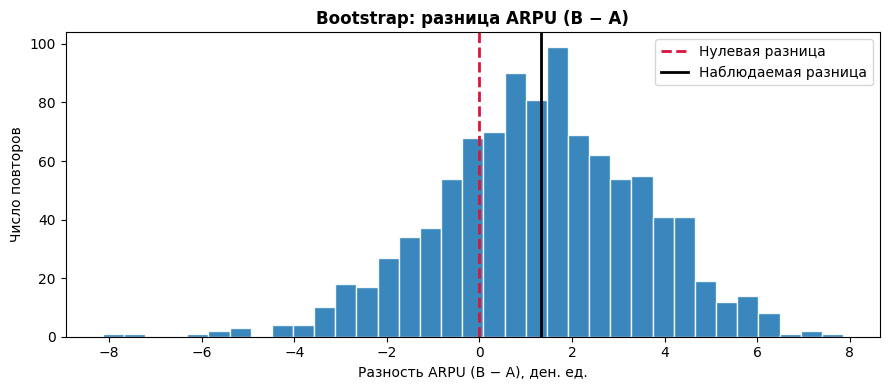

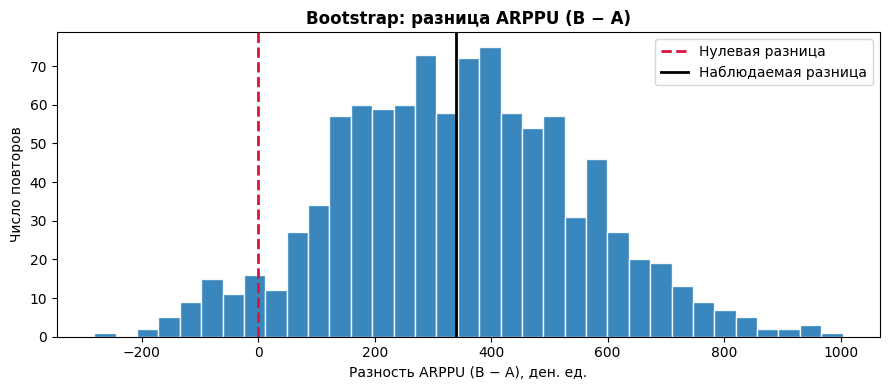

In [9]:
if 'results' in globals():
    for metric, result in results.items():
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.hist(result['bootstrap_differences'], bins=35, edgecolor='white', alpha=0.88)
        ax.axvline(0, color='crimson', linestyle='--', linewidth=2, label='Нулевая разница')
        ax.axvline(result['observed_difference'], color='black', linewidth=2, label='Наблюдаемая разница')
        ax.set_title(f'Bootstrap: разница {metric} (B − A)', weight='bold')
        ax.set_xlabel(f'Разность {metric} (B − A), ден. ед.')
        ax.set_ylabel('Число повторов')
        ax.legend()
        plt.tight_layout()
        fig.savefig(RESULTS_DIR / f'bootstrap_{metric.lower()}.png', dpi=160, bbox_inches='tight')
        plt.show()

## Результаты A/B-теста

| Показатель | Контроль A | Тест B |
| --- | ---: | ---: |
| Пользователи | 202 103 | 202 667 |
| Платящие пользователи | 1 928 | 1 805 |
| Суммарная выручка | 5 136 189 | 5 421 603 |
| CR, % | 0,95397 | 0,89062 |
| ARPU | 25,41372 | 26,75129 |
| ARPPU | 2 663,99844 | 3 003,65817 |

Конверсия в B ниже на 0,06335 процентного пункта. Двусторонний z-тест дает `p = 0,03503`; различие значимо при номинальном уровне 0,05 без поправки на множественные сравнения.

| Метрика | Разность B минус A | 95%-й bootstrap-интервал |
| --- | ---: | --- |
| ARPU | 1,33757 | [−3,13891; 5,58430] |
| ARPPU | 339,65973 | [−71,81741; 761,71698] |

Наблюдаемые ARPU и ARPPU выше в B, однако оба доверительных интервала включают ноль и допускают как рост, так и снижение. Рост денежных метрик не подтвержден; снижение CR представляет дополнительный риск для тестового варианта. По результатам анализа оснований рекомендовать внедрение B не получено. Рекомендация: сохранить контрольный набор A.

Bootstrap-интервалы рассчитаны при `random_state=42` и 1 000 повторах; их границы имеют симуляционную погрешность. Номинальные результаты нескольких проверок не образуют единого критерия принятия решения с контролем общей вероятности ошибки. Основная метрика и правило решения задаются на этапе планирования эксперимента.


<a id="task-3"></a>
# Задание 3. Метрики игровых событий

## Постановка задачи

Определить систему показателей для тематического игрового события с уровнями и наградами. Дополнить систему для механики, в которой поражение вызывает откат прогресса.

## Метрики базового события

Для оценки прохождения основная метрика представляет долю участников, завершивших событие. Участником считается игрок, начавший хотя бы одну попытку. Завершение определяется прохождением финального этапа в пределах периода события. Охват, удержание и монетизация дополняют оценку прохождения.

| Область | Показатели и расчет |
| --- | --- |
| Охват | Уникальные участники и их доля среди игроков, имеющих право участия |
| Завершение | Доля участников, прошедших финальный этап; доля получивших финальную или уникальную награду |
| Прогресс | Среднее и медианное число уникальных пройденных уровней, максимальный достигнутый этап, доля участников, достигших каждого этапа |
| Награды | Распределение полученных предметов, монет и бонусов по участникам и этапам |
| Активность | Число попыток, активных игровых сессий и действий в событии на участника |
| Прекращение прохождения | Этапы, после которых участники не продолжают прохождение в установленном окне наблюдения |

Награды анализируются вместе с прогрессом, поскольку их получение зависит от пройденных этапов. Время открытого приложения не равно времени активной игры; для оценки вовлеченности используются сессии и игровые действия.

Для метрики прекращения прохождения окно бездействия фиксируется до расчета. В знаменатель включаются только игроки, для которых это окно полностью наблюдалось до завершения события. Уникальные пройденные уровни, максимальный этап и повторные прохождения учитываются раздельно.

### Удержание и активная аудитория

Удержание D1 и D7 после события определяется активностью в игре на первый и седьмой календарный день после его окончания. Дополнительно анализируются размер активной аудитории и число игровых дней на пользователя. Календарь, часовой пояс и состав знаменателя одинаковы для сравниваемых групп.

Участники события исходно могут быть активнее неучастников. Поэтому сравнение этих категорий описывает различия аудитории и само по себе не оценивает эффект события.

### Монетизация

За одинаковый период рассчитываются ARPU, доля платящих и ARPPU, суммарная выручка и число покупок, связанных с событием. Денежные показатели рассматриваются вместе с прохождением, удержанием и активностью.

## Событие с откатом после поражения

Базовая система метрик сохраняется. Для оценки сложности и потери прогресса добавляются следующие показатели:

| Показатель | Определение |
| --- | --- |
| Частота неудач | Доля проигранных попыток и число попыток до успешного прохождения уровня |
| Охват откатами | Доля участников, испытавших хотя бы один откат |
| Частота и глубина откатов | Число откатов и число потерянных уровней на участника; распределение глубины отката |
| Застревание | Этапы с высокой долей повторных попыток и прекращения продвижения |
| Прекращение участия после отката | Доля игроков, прекративших участие после поражения или серии откатов, при полностью наблюдаемом окне бездействия |
| Эффективность прогресса | Чистое изменение достигнутого этапа на попытку или активную сессию |

Приоритетные показатели версии с откатами: доля завершивших событие, прекращение участия после отката и глубина откатов. Они выявляют этапы, где потеря прогресса сопровождается повышенной долей прекращения участия. Наблюдаемая связь не устанавливает причину ухода.

## Оценка эффекта события

Причинный эффект оценивается в рандомизированном эксперименте среди игроков, имеющих право участия. Метрики сравниваются по назначенным группам при одинаковых условиях и сроках наблюдения. Охват рассчитывается среди всей доступной аудитории группы; прохождение среди участников дополняется показателями по всей назначенной группе.

Простое сравнение участников и неучастников подвержено самоотбору. Наблюдательные сравнения требуют дополнительных предположений о сопоставимости групп. Для механики отката применяются те же правила сравнения с версией события без отката.


## Контроль объема расчета

Проверяется количество строк и уникальных пользователей в каждой таблице, соответствие горизонта retention дням от 0 до 30 и равенство D0 100% для данного набора.


In [10]:
assert USE_SAMPLE is False
assert len(reg_work) == 1_000_000 and reg_work['uid'].nunique() == 1_000_000
assert len(auth_work) == 9_601_013 and auth_work['uid'].nunique() == 1_000_000
assert len(ab_data) == 404_770 and ab_data['user_id'].nunique() == 404_770
assert ab_metrics['users_cnt'].sum() == len(ab_data)
assert retention_matrix.columns.tolist() == list(range(31))
assert np.allclose(retention_matrix[0].dropna(), 100)
run_coverage = pd.DataFrame([
    {'dataset': 'registrations', 'rows': len(reg_work), 'users': reg_work['uid'].nunique()},
    {'dataset': 'authorizations', 'rows': len(auth_work), 'users': auth_work['uid'].nunique()},
    {'dataset': 'ab_test', 'rows': len(ab_data), 'users': ab_data['user_id'].nunique()},
])
run_coverage.to_csv(RESULTS_DIR / 'run_coverage.csv', index=False)
display(run_coverage)
print('Каталог результатов: full_results/')


,dataset,rows,users
0,registrations,1000000,1000000
1,authorizations,9601013,1000000
2,ab_test,404770,404770


Каталог результатов: full_results/


<a id="summary"></a>
# Итоги проекта

1. Рассчитан дневной когортный retention по 1 000 000 игроков и 9 601 013 авторизаций. Матрица включает 5 110 когорт и дни жизни от 0 до 30. Повторные входы в один день учитываются однократно, дни за пределами наблюдения обозначены `NaN`. Тепловая карта показывает последние 20 когорт.
2. Проведен A/B-анализ по 404 770 пользователям. Рассчитаны CR, ARPU и ARPPU, выполнены z-тест двух пропорций и bootstrap разности средних. Рост ARPU и ARPPU в B не подтвержден доверительными интервалами. CR ниже в B при номинальном уровне значимости 0,05 без поправки на несколько проверок. Рекомендовано сохранить контрольный набор A.
3. Определены метрики прохождения, охвата, активности, удержания и монетизации игрового события. Для версии с откатами добавлены показатели неудач, потери прогресса, застревания и прекращения участия. Оценка причинного эффекта опирается на сравнение рандомизированных групп.
